# 19 · Tabular foundation models (E47)

Pretrained tabular transformers predict from the training rows in context, with no tuning. Do they beat the final CatBoost model, or add to it in an average?
- **TabPFN v2** regressor, median of the predictive distribution (weights `tabpfn-v2-regressor.ckpt`, Apache-2.0 with attribution: *Built with PriorLabs-TabPFN*);
- **TabICL v2** regressor (BSD-3).

Same features as the final model (followers + reactions + missing flags), the same 5 brand-grouped folds, every model averaged over seeds 0/1/2, CPU only, data stay on homelab3. Settings fixed before the run (a pilot with one seed suggested a YouTube gain).

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import extra_models as em, history as H, tabular_foundation as tf

FIG = ROOT / "figures"; plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220, "display.max_columns", 30)
B = "CatBoost (final model)"

In [2]:
f, meta = em.load(ROOT)
P, times = tf.run(f, meta)
times.pivot(index="model", columns="platform", values="seconds")[tf.PLATS].round(0)

platform,tiktok,youtube,twitter
model,,,
CatBoost (final model),2.0,1.0,1.0
TabICL,166.0,183.0,119.0
TabPFN v2,198.0,163.0,95.0


## 1 · MAE per model

In [3]:
S = H.summarise(P); S.round(3)

,platform,model,posts,MAE,CI low,CI high,bias
0,tiktok,CatBoost (final model),2491,0.273,0.262,0.284,-0.020
1,tiktok,TabPFN v2,2491,0.268,0.258,0.279,-0.012
2,tiktok,TabICL,2491,0.272,0.260,0.282,-0.002
3,tiktok,mean CatBoost + TabPFN,2491,0.269,0.259,0.280,-0.016
4,tiktok,mean CatBoost + TabICL,2491,0.270,0.260,0.281,-0.011
5,tiktok,mean of all three,2491,0.269,0.259,0.280,-0.011
6,youtube,CatBoost (final model),2441,0.453,0.431,0.477,-0.041
7,youtube,TabPFN v2,2441,0.443,0.420,0.467,-0.041
8,youtube,TabICL,2441,0.445,0.424,0.468,0.015
9,youtube,mean CatBoost + TabPFN,2441,0.445,0.423,0.469,-0.041


## 2 · Paired gain over the final model
All posts, posts with zero likes and comments (E27: possibly missing data), and the rest.

In [4]:
subs = {"all posts": P, "zero likes and comments": P[P.zero], "with reactions": P[~P.zero]}
G = pd.DataFrame([{"platform": p, "model": k, "subset": s, "posts": int(((Q.platform == p) & (Q.model == B)).sum()), **dict(zip(["gain", "CI low", "CI high"], H.gain_ci(Q, p, B, k)))}
                  for s, Q in subs.items() for p in tf.PLATS for k in tf.SINGLE[1:] + list(tf.MEANS)])
G[G.subset == "all posts"].round(3)

,platform,model,subset,posts,gain,CI low,CI high
0,tiktok,TabPFN v2,all posts,2491,0.005,0.003,0.008
1,tiktok,TabICL,all posts,2491,0.001,-0.002,0.005
2,tiktok,mean CatBoost + TabPFN,all posts,2491,0.004,0.002,0.005
3,tiktok,mean CatBoost + TabICL,all posts,2491,0.003,0.001,0.005
4,tiktok,mean of all three,all posts,2491,0.004,0.002,0.006
5,youtube,TabPFN v2,all posts,2441,0.010,0.004,0.017
6,youtube,TabICL,all posts,2441,0.008,0.002,0.014
7,youtube,mean CatBoost + TabPFN,all posts,2441,0.009,0.006,0.012
8,youtube,mean CatBoost + TabICL,all posts,2441,0.008,0.004,0.011
9,youtube,mean of all three,all posts,2441,0.010,0.006,0.014


In [5]:
G[G.subset != "all posts"].pivot_table(index=["platform", "model"], columns="subset", values=["posts", "gain", "CI low"], sort=False).round(3)

posts                                   gain                                 CI low               
subset                          zero likes and comments with reactions zero likes and comments with reactions zero likes and comments with reactions
platform model                                                                                                                                      
tiktok   TabPFN v2                                 90.0         2401.0                   0.007          0.005                  -0.011          0.003
         TabICL                                    90.0         2401.0                  -0.019          0.002                  -0.081         -0.001
         mean CatBoost + TabPFN                    90.0         2401.0                   0.005          0.004                  -0.004          0.003
         mean CatBoost + TabICL                    90.0         2401.0                   0.002          0.003                  -0.029          0.001
         mean of all three                         90.0         2401.0                   0.005          0.004                  -0.023          0.002
youtube  TabPFN v2                                665.0         1776.0                   0.012          0.010                  -0.003          0.002
         TabICL                                   665.0         1776.0                   0.014          0.006                   0.004         -0.002
         mean CatBoost + TabPFN                   665.0         1776.0                   0.012          0.008                   0.004          0.004
         mean CatBoost + TabICL                   665.0         1776.0                   0.009          0.007                   0.004          0.003
         mean of all three                        665.0         1776.0                   0.014          0.009                   0.006          0.004
twitter  TabPFN v2                                991.0          812.0                  -0.001          0.006                  -0.006         -0.002
         TabICL                                   991.0          812.0                  -0.001          0.003                  -0.005         -0.007
         mean CatBoost + TabPFN                   991.0          812.0                   0.000          0.005                  -0.003          0.001
         mean CatBoost + TabICL                   991.0          812.0                  -0.000          0.004                  -0.002         -0.000
         mean of all three                        991.0          812.0                   0.000          0.005                  -0.002          0.000

## 3 · Gain by reaction tier (all three averaged)

In [6]:
K = "mean of all three"
R = pd.DataFrame([{"platform": p, "tier": t, "posts": int(((P.platform == p) & (P.model == B) & (P.tier == t)).sum()), **dict(zip(["gain", "CI low", "CI high"], H.gain_ci(P[P.tier == t], p, B, k)))}
                  for p in tf.PLATS for t in ["0", "1-10", "11-100", "101-1000", ">1000"] for k in [K] if ((P.platform == p) & (P.tier == t)).sum() >= 30])
R.round(3)

,platform,tier,posts,gain,CI low,CI high
0,tiktok,0,84,0.004,-0.025,0.030
1,tiktok,1-10,526,0.000,-0.002,0.004
2,tiktok,11-100,1120,0.001,-0.001,0.002
3,tiktok,101-1000,532,0.005,0.002,0.007
4,tiktok,>1000,229,0.026,0.012,0.040
5,youtube,0,665,0.014,0.006,0.022
6,youtube,1-10,613,0.016,0.006,0.026
7,youtube,11-100,631,0.004,-0.001,0.009
8,youtube,101-1000,394,0.006,-0.001,0.012
9,youtube,>1000,138,0.011,-0.011,0.030


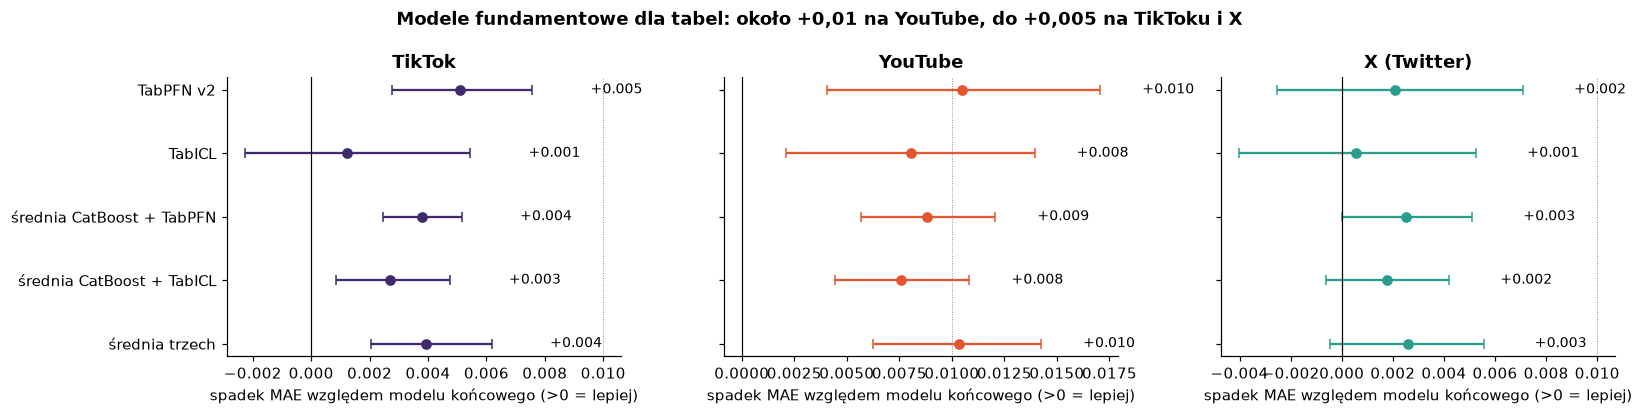

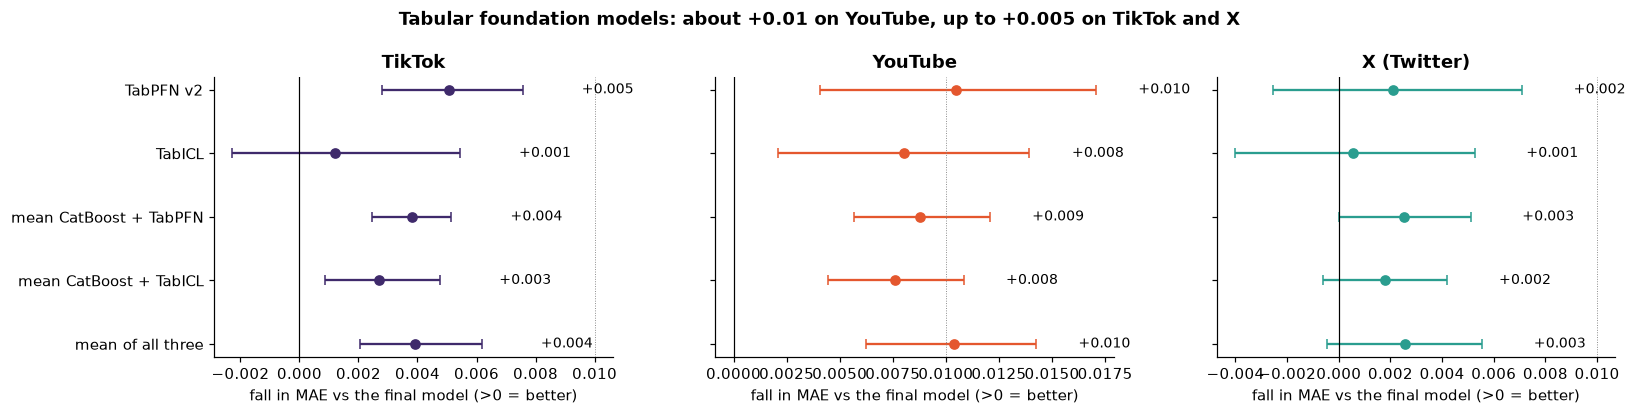

In [7]:
for l in ("pl", "en"): tf.plot(G, FIG / f"tabular_foundation_{l}.png", l)

## Takeaways
See `docs/en/experiments.md` (E47) and `agent/vault/E47.md`. Numbers: `data/processed/tabular_foundation_numbers.json`.

In [8]:
json.dump({"models": S.to_dict("records"), "gains": G.to_dict("records"), "by_tier": R.to_dict("records"), "seconds": times.to_dict("records")},
          open(ROOT / "data" / "processed" / "tabular_foundation_numbers.json", "w"), indent=1, default=float)